<a href="https://colab.research.google.com/github/Luiz-FelipeDev/Desafio-Itau-Java/blob/main/04_Notebook_Pandas_Parte_1_Fundamentos_de_Series_e_DataFrame.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

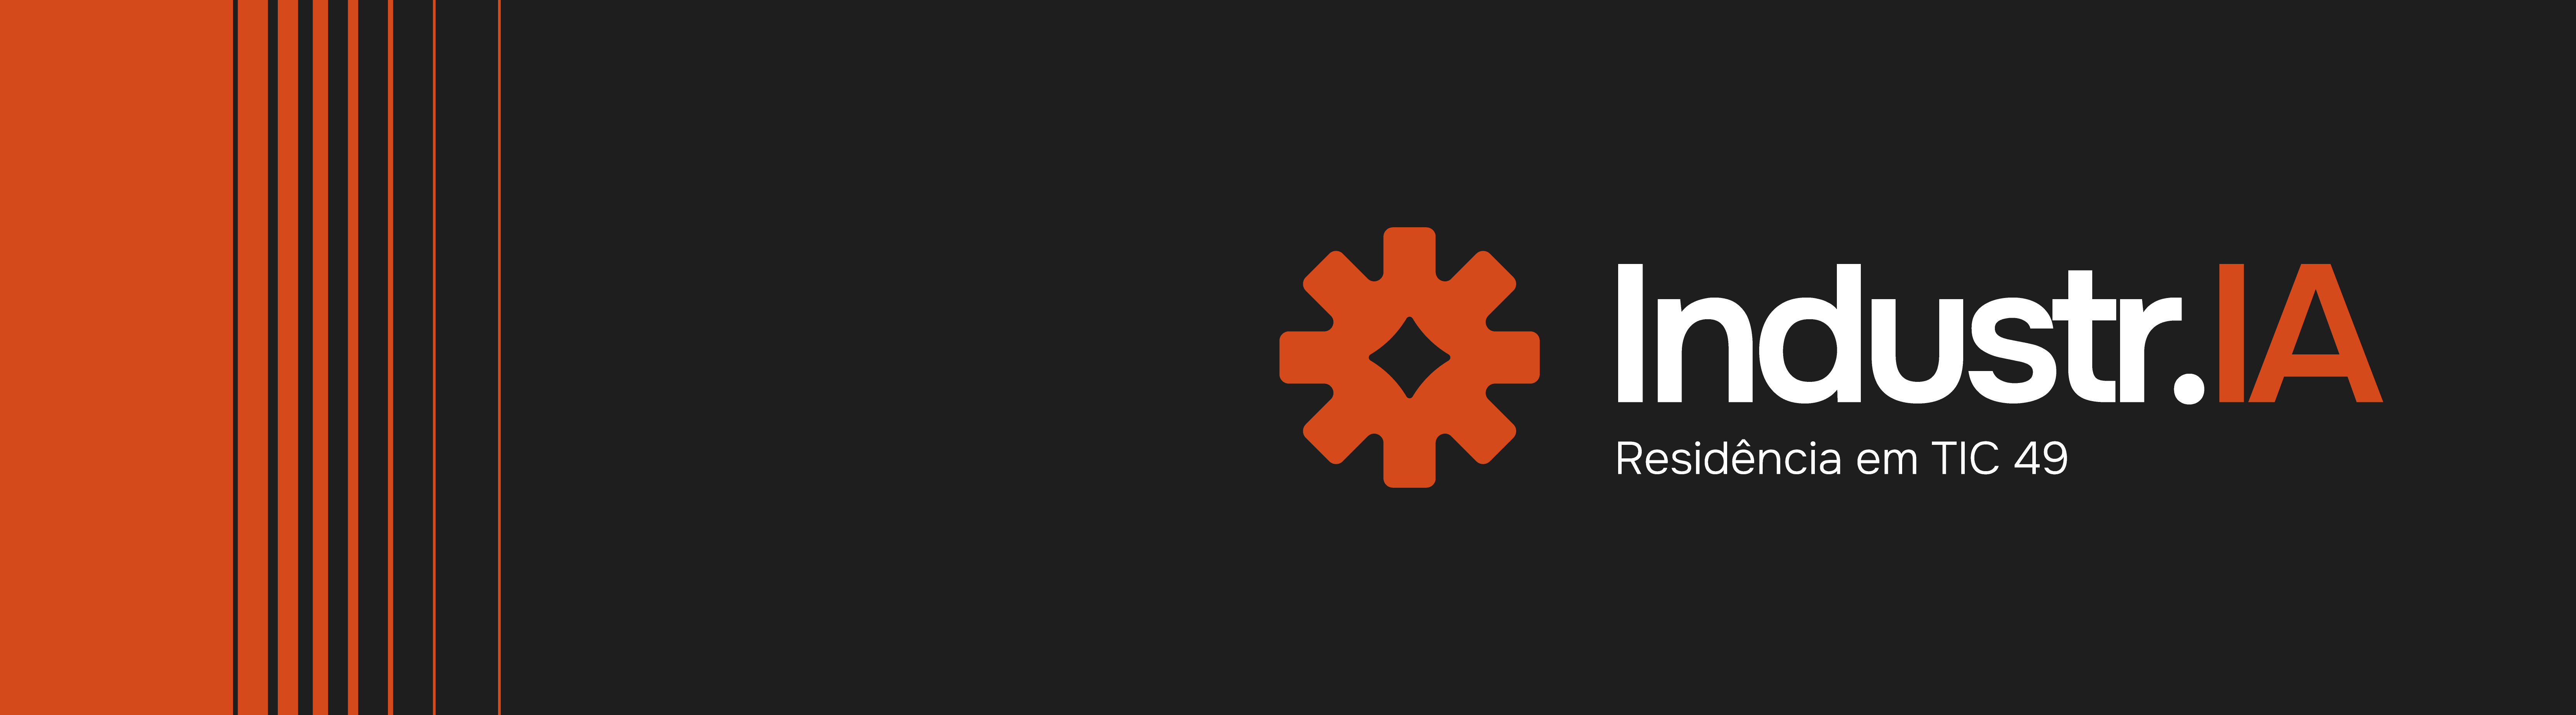

# Introdução à Programação com IA

## 📘 Bloco B2: Pandas Parte 1 - Fundamentos de Series e DataFrame

---

### 🎯 Visão Geral do Bloco

Neste bloco, você dará os primeiros passos na principal biblioteca de análise de dados do ecossistema Python: o **Pandas**. Ao final deste bloco, você será capaz de criar e estruturar dados tabulares a partir de diferentes fontes, explorar seu conteúdo e realizar operações fundamentais de seleção, filtragem e organização de informações.

Você aprenderá a trabalhar com as duas estruturas centrais da biblioteca:

- **Series**: coleções unidimensionais de dados.
- **DataFrames**: tabelas bidimensionais compostas por linhas e colunas.

Além disso, veremos como importar dados de arquivos CSV, inspecionar conjuntos de dados, selecionar registros específicos e aplicar filtros para extrair informações relevantes.

Essas competências servirão de base para todas as etapas posteriores de preparação e análise de dados em projetos de Inteligência Artificial.

---

## 📖 Glossário de Termos

Caso tenha alguma dúvida sobre qualquer termo técnico utilizado nesta aula, você pode acessar o nosso material de consulta rápida clicando no link abaixo:

👉 Acessar o Glossário de Termos Técnicos deste Bloco

**Dica: Deixe o glossário aberto em uma aba ao lado para consultar na medida que apareçam as dúvidas.**

## Seção 1: Introdução ao Pandas

Em projetos de Inteligência Artificial, raramente os dados chegam prontos para uso. Antes de treinar modelos ou construir análises, é necessário organizar, inspecionar e compreender as informações disponíveis. É exatamente para essa finalidade que utilizamos o **Pandas**.

O Pandas é uma das bibliotecas mais populares do ecossistema Python para manipulação e análise de dados estruturados. Ele oferece estruturas de dados flexíveis e eficientes que permitem trabalhar com tabelas de forma semelhante a planilhas eletrônicas ou bancos de dados.

🚀 Principais Vantagens:

* Manipulação Simplificada de Dados: Permite criar, modificar e consultar conjuntos de dados utilizando comandos intuitivos.

* Integração com Diversas Fontes: Suporta leitura e escrita de arquivos CSV, Excel, JSON, bancos de dados e diversas outras origens de dados.

* Alto Desempenho: Construído sobre o NumPy, aproveita operações otimizadas para processar grandes volumes de dados.

* Ferramentas para Análise Exploratória: Possui recursos nativos para inspeção, estatísticas descritivas, filtragem e transformação de dados.

Ao longo deste bloco, você aprenderá a trabalhar com as duas estruturas fundamentais do Pandas: **Series** e **DataFrames**, que servem de base para praticamente todas as tarefas de preparação e análise de dados em Ciência de Dados e Inteligência Artificial.




### `Series`: O Array Unidimensional Rotulado

Uma `Series` é uma estrutura unidimensional baseada em um ndarray do NumPy, mantendo a característica de tipagem homogênea (um único dtype - tipo de dado - por estrutura). Sobre essa base, o Pandas adiciona índices rotulados (labels), permitindo seleção por nome e operações com alinhamento automático de índices.

In [1]:
import numpy as np
import pandas as pd

# A partir de uma lista: os índices padrões são números inteiros com início no índice zero.
s1 = pd.Series([10, 20, 30, 40, 50],
               name = 'Dezenas',
               dtype='int16')
print(f"Exemplo com índices padrões:\n{s1}\n")

# Com índice personalizados: aqui define-se letras como índices ('6', '7', '8', '9' e '10').
s2 = pd.Series([10, 20, 30, 40, 50],
               index=range(6,11),
               name = 'Dezenas',
               dtype='int16')
print(f"Exemplo com índices letras:\n{s2}\n")

# A partir de um dicionário (índice = chaves)
s3 = pd.Series({'a': 10, 'b': 20, 'c': 30, 'd': 40,'e': 50},
               name = 'Dezenas',
               dtype='int16')
print(f"Exemplo com dicionário:\n{s3}\n")

# Diretamente a partir de um array NumPy
s4 = pd.Series(np.arange(10,51, 10),
               index=list('abcde'),
               name = 'Dezenas',
               dtype='int16')
print(f"Exemplo com numpy:\n{s4}\n")

Exemplo com índices padrões:
0    10
1    20
2    30
3    40
4    50
Name: Dezenas, dtype: int16

Exemplo com índices letras:
6     10
7     20
8     30
9     40
10    50
Name: Dezenas, dtype: int16

Exemplo com dicionário:
a    10
b    20
c    30
d    40
e    50
Name: Dezenas, dtype: int16

Exemplo com numpy:
a    10
b    20
c    30
d    40
e    50
Name: Dezenas, dtype: int16



### ❗ dtype

O `dtype` define o tipo de dado armazenado de forma homogênea em uma coluna de DataFrame (cada coluna uma `Serie`). Essa homogeneidade permite que o pandas explore operações vetorizadas, aproveitando a mesma eficiência estrutural do NumPy.

Os tipos mais comuns incluem:

##### Numéricos
- `int64` → inteiros (ex: 1, 20, -5)
- `float64` → números reais (ex: 3.14, 0.001)

##### Booleano
- `bool` → valores lógicos (`True` / `False`)

##### Texto
- `string` → tipo moderno e mais consistente para texto

##### Datas e tempo
- `datetime64[ns]` → datas e horários
- `timedelta[ns]` → diferença entre datas/tempos

##### Categóricos (otimização de memória)
- `category` → valores repetidos com vocabulário fixo (ex: sexo, estado civil, classes)

##### Estruturados / avançados
- `complex128` → números complexos

### dtype	Bytes por valor	Intervalo(Importante para TinyML)
- int8	1	-128 a 127
- int16	2	-32.768 a 32.767
- int32	4	≈ -2,1 bilhões a 2,1 bilhões
- int64	8	≈ -9,2 quintilhões a 9,2 quintilhões

### 💡 Pratique: Criando uma Series

Um meteorologista precisa analisar o comportamento da precipitação chuvosa ao longo de um ano. Ele coletou dados diários de precipitação (em milímetros) durante **356 dias** (índices: 'Dia 1', 'Dia 2', etc.).

Utilize a função ⚙️ `np.random.uniform` (apresentada no Bloco B1) para gerar valores de precipitação diária entre **0 mm e 85 mm**.

Em seguida:

1. Exiba a Series.
2. Exiba o tipo dos dados armazenados.

In [37]:
# Sua solução aqui.

precipitacao = np.random.uniform(low=10, high=85, size=(356,))
indices = [f"Dia{i}" for i in range(1, 357)]

series_chuva = pd.Series(precipitacao, index=indices, dtype='float64', name='Precipitação(mm)')

series_chuva

#Aplicando isso dentro de uma Series

,Precipitação(mm)
Dia1,32.360428
Dia2,61.314781
Dia3,20.612990
Dia4,10.339779
Dia5,84.853688
...,...
Dia352,78.134487
Dia353,57.057132
Dia354,83.645165
Dia355,20.988213


### `Dataframes`: A Estrutura Tabular Bidimensional

O `DataFrame` é uma estrutura tabular bidimensional formada por Series que compartilham o mesmo índice, onde cada coluna pode ter um tipo de dado diferente.

Internamente, o Pandas organiza os dados de forma otimizada para operações vetorizadas, podendo agrupar colunas de tipos compatíveis em blocos de memória (como no `BlockManager`), embora a implementação atual também inclua outras estratégias de armazenamento.

In [3]:
# DataFrame a partir de dicionário de listas (forma mais comum)

df = pd.DataFrame({
    "nome": pd.Series(["Ana", "Bruno", "Carlos", "Diana"],
                      dtype="string"),
    "idade": pd.Series([23, 35, 29, 41],
                       dtype="int16"), # limites de representação: (-32.768 a 32.767)
    "salario": pd.Series([2500.0, 4800.5, 3200.0, 5100.0],
                         dtype="float32")
})

print(f"DataFrame básico:\n{df}\n")

DataFrame básico:
     nome  idade  salario
0     Ana     23   2500.0
1   Bruno     35   4800.5
2  Carlos     29   3200.0
3   Diana     41   5100.0



### ❗ Labels (Índices e Colunas)

No Pandas, os labels (rótulos) são um conceito central. Diferentemente de um array do NumPy, que utiliza apenas posições inteiras para acessar os elementos, o Pandas permite atribuir rótulos aos eixos dos dados:

Linhas → por meio do atributo `index` (em `Series` e `DataFrame`);

Colunas → por meio do atributo `columns` (em `DataFrame`).

Essa capacidade de rotular linhas e colunas é uma das principais razões pelas quais o Pandas se tornou tão popular para análise de dados, pois torna o código mais legível, intuitivo e próximo da forma como os dados são representados no mundo real.

### 💡 Pratique: Criando um DataFrame

Uma fábrica de autopeças monitora diariamente o desempenho de **4 máquinas** ao longo de 30 dias. Os dados coletados incluem:

- Temperatura média do motor (°C)
- Vibração (mm/s)
- Horas de operação
- Consumo de energia (kWh)

Crie um DataFrame utilizando as seguintes estruturas.

```python
lista_dias = [f"Dia {i+1}" for i in range(30)]

dicionario_dados = {
    "Temperatura_Motor_C": np.random.uniform(low=65, high=95, size=30),
    "Vibracao_mm_s": np.random.uniform(low=0.8, high=4.5, size=30),
    "Horas_Operacao": np.random.uniform(low=18, high=24, size=30),
    "Consumo_Energia_kWh": np.random.uniform(low=420, high=680, size=30)
}
```

Após criar o DataFrame exiba as primeiras 8 linhas iniciais.

In [38]:
# Sua solução aqui.

lista_dias = [f"Dia {i+1}" for i in range(30)]

dicionario_dados = {
    "Temperatura_Motor_C": np.random.uniform(low=65, high=95, size=30),
    "Vibracao_mm_s": np.random.uniform(low=0.8, high=4.5, size=30),
    "Horas_Operacao": np.random.uniform(low=18, high=24, size=30),
    "Consumo_Energia_kWh": np.random.uniform(low=420, high=680, size=30)
}

{'Temperatura_Motor_C': array([80.15756653, 94.36418427, 73.91022121, 93.50195998, 93.10373487,
        89.4591575 , 87.47928569, 78.34671356, 74.95810798, 85.97629405,
        91.24146636, 68.14665698, 91.68851267, 78.36431475, 70.66243316,
        70.15872909, 73.42849485, 66.27458526, 77.62781567, 78.43809207,
        84.32948822, 69.03709582, 86.28148621, 75.63205094, 93.93595774,
        92.53295278, 68.60456578, 66.75571254, 67.58039466, 81.73571249]),
 'Vibracao_mm_s': array([2.12625607, 2.74304933, 4.08773988, 1.63694307, 2.62278918,
        4.46162063, 2.48744067, 3.85679478, 1.0863242 , 3.08073123,
        2.0373806 , 1.46033772, 1.69005146, 1.13154077, 3.82333405,
        3.09359578, 1.90098701, 3.14670908, 2.08640608, 1.60143184,
        4.36794996, 3.70343905, 1.86497608, 1.07793351, 3.13987462,
        4.03635899, 0.87310747, 0.94927556, 0.97841809, 0.80299441]),
 'Horas_Operacao': array([22.97579459, 22.49605736, 21.09539569, 19.22707993, 21.87628653,
        19.54235413

### ⚙️ Calibração de Sensores em uma Siderúrgica

Vamos retomar nosso exemplo da calibração de sensores. Uma siderúrgica possui 50 fornos, cada um monitorado por um sensor de temperatura. Durante 365 dias, foi registrada a temperatura média diária de cada forno.

In [5]:
import pandas as pd
import numpy as np

# Matriz de temperaturas: 365 dias × 50 fornos
temperaturas = pd.DataFrame(
    np.random.normal(loc=1200, scale=50, size=(365, 50)),
    columns=[f'Forno_{i+1:02d}' for i in range(50)],
    index=pd.date_range('2025-01-01', periods=365, freq='D')
)

print("Shape:", temperaturas.shape)

# Observando as primeiras 5 linhas.
temperaturas.head()

Shape: (365, 50)


,Forno_01,Forno_02,Forno_03,Forno_04,Forno_05,Forno_06,Forno_07,Forno_08,Forno_09,Forno_10,...,Forno_41,Forno_42,Forno_43,Forno_44,Forno_45,Forno_46,Forno_47,Forno_48,Forno_49,Forno_50
2025-01-01,1211.070021,1175.865314,1269.135859,1233.082858,1247.216862,1231.905649,1139.307540,1180.419808,1159.898638,1137.054969,...,1196.003139,1195.021137,1236.403367,1156.807294,1324.553257,1224.902492,1172.961923,1260.003493,1220.254195,1154.095941
2025-01-02,1131.196914,1229.345932,1184.077508,1233.446656,1275.064038,1130.989791,1212.244400,1180.619442,1205.003373,1155.309521,...,1166.225576,1191.249312,1249.470034,1251.576709,1081.913611,1242.943243,1247.983698,1166.581520,1286.140376,1149.940957
2025-01-03,1230.714977,1161.066517,1258.509913,1217.412222,1189.011803,1110.944578,1307.723109,1111.792742,1221.674469,1231.195496,...,1121.248517,1244.186919,1232.464723,1213.149693,1168.755811,1198.427971,1123.665346,1243.872424,1162.015706,1168.450300
2025-01-04,1218.207371,1107.568795,1300.275948,1250.256606,1183.346063,1156.094160,1209.134807,1316.206133,1070.592737,1212.737461,...,1219.944349,1214.040703,1222.759906,1186.382924,1142.091707,1164.177094,1262.123330,1190.049134,1233.174014,1069.846368
2025-01-05,1210.523205,1189.534665,1255.022698,1200.287713,1269.735674,1177.278033,1194.891350,1274.239467,1276.064670,1225.696491,...,1163.722993,1288.221267,1181.792254,1189.849905,1179.143230,1212.280618,1086.559950,1209.689036,1109.074531,1200.110252


Após inspeção, descobriu-se que cada sensor possui um erro de calibração (offset) diferente:

In [6]:
offsets = pd.Series(
    np.random.uniform(low=-10, high=10, size=50),
    index=temperaturas.columns,
    name='offset'
)

Corrigindo as leituras subtraindo o offset de cada coluna (`Broadcasting` no Pandas).

In [7]:
# Pandas faz o alinhamento automático pelos nomes das colunas
temperaturas_calibradas = temperaturas - offsets

# Verificando os primeiros valores
print("Offsets aplicados com sucesso!")
temperaturas_calibradas.head(3)

Offsets aplicados com sucesso!


,Forno_01,Forno_02,Forno_03,Forno_04,Forno_05,Forno_06,Forno_07,Forno_08,Forno_09,Forno_10,...,Forno_41,Forno_42,Forno_43,Forno_44,Forno_45,Forno_46,Forno_47,Forno_48,Forno_49,Forno_50
2025-01-01,1211.152825,1180.252228,1270.825957,1233.635631,1247.145163,1241.233667,1135.121789,1189.762496,1161.958683,1142.847633,...,1200.190405,1186.493011,1229.405748,1151.743188,1324.571821,1228.903656,1176.702452,1260.574925,1230.140744,1145.249898
2025-01-02,1131.279718,1233.732847,1185.767606,1233.999430,1274.992339,1140.317810,1208.058649,1189.962130,1207.063417,1161.102186,...,1170.412842,1182.721185,1242.472415,1246.512603,1081.932174,1246.944408,1251.724227,1167.152952,1296.026925,1141.094914
2025-01-03,1230.797781,1165.453432,1260.200011,1217.964996,1188.940103,1120.272596,1303.537358,1121.135431,1223.734514,1236.988160,...,1125.435782,1235.658792,1225.467104,1208.085588,1168.774374,1202.429136,1127.405875,1244.443856,1171.902256,1159.604257


Observe que `offsets` é uma **Series**, enquanto `temperaturas` é um **DataFrame**.

**DataFrame `temperaturas`**

| Índice | Forno1 | Forno2 | ... | Forno50 |
|--------:|--------|--------|-----|---------|
| Dia 1   | T₁₁    | T₁₂    | ... | T₁₅₀    |
| Dia 2   | T₂₁    | T₂₂    | ... | T₂₅₀    |
| ...     | ...    | ...    | ... | ...     |
| Dia 365 | T₃₆₅₁  | T₃₆₅₂  | ... | T₃₆₅₅₀  |

**Series `offsets`**

| Forno1 | Forno2 | ... | Forno50 |
|--------|--------|-----|---------|
| Off₁   | Off₂   | ... | Off₅₀   |

Ao executar:

```python
temperaturas - offsets
```

o Pandas aplica **broadcasting**: a `Series` é alinhada pelos **labels das colunas** e replicada virtualmente para todas as linhas do `DataFrame`.

```
                    Broadcasting

DataFrame (365 × 50)        Series (50,)
┌──────────────────────┐     ┌──────────────┐
│ Dia 1   T₁₁ T₁₂ ...  │     │ Off₁ Off₂... │
│ Dia 2   T₂₁ T₂₂ ...  │  ─► └──────────────┘
│ ...                  │     
│ Dia365  T...         │
└──────────────────────┘

              ↓

Series replicada virtualmente

┌──────────────────────┐
│ Off₁ Off₂ ... Off₅₀  │
│ Off₁ Off₂ ... Off₅₀  │
│ ...                  │
│ Off₁ Off₂ ... Off₅₀  │
└──────────────────────┘
```

A operação efetivamente realizada é:

| Índice | Forno1 | Forno2 | ... | Forno50 |
|--------:|--------|--------|-----|---------|
| Dia 1   | T₁₁−Off₁ | T₁₂−Off₂ | ... | T₁₅₀−Off₅₀ |
| Dia 2   | T₂₁−Off₁ | T₂₂−Off₂ | ... | T₂₅₀−Off₅₀ |
| ...     | ...      | ...      | ... | ...         |
| Dia 365 | T₃₆₅₁−Off₁ | T₃₆₅₂−Off₂ | ... | T₃₆₅₅₀−Off₅₀ |

> **Importante:** a replicação da `Series` é apenas conceitual. O Pandas não cria uma cópia física com 365 linhas; ele realiza a operação utilizando *broadcasting*, de forma semelhante ao NumPy, preservando o alinhamento pelos **labels** das colunas.

## Seção 2: Criando DataFrames a partir de Diferentes Fontes

Uma das principais vantagens do Pandas é sua capacidade de criar estruturas tabulares a partir de diversas origens de dados. Em projetos reais, os dados podem vir de planilhas, bancos de dados, APIs, arquivos CSV ou até mesmo estruturas já existentes em Python.

### DataFrame a partir de Listas

Uma lista de listas pode ser utilizada para representar linhas de uma tabela.

In [8]:
import pandas as pd

dados = [
    ["Ana", 21, "São Paulo"],
    ["Bruno", 24, "Niterói"],
    ["Carla", 22, "Recife"]
]

df = pd.DataFrame(
    dados,
    columns=["Nome", "Idade", "Cidade"]
)

df.head()

,Nome,Idade,Cidade
0,Ana,21,São Paulo
1,Bruno,24,Niterói
2,Carla,22,Recife


### DataFrame a partir de Dicionários

Outra abordagem muito utilizada é a criação a partir de dicionários.

Nesse caso, cada chave do dicionário corresponde a uma coluna do DataFrame.

Essa é uma das formas mais populares de construção de tabelas em Pandas devido à sua simplicidade e legibilidade.

In [9]:
dados = {
    "Nome": ["Ana", "Bruno", "Carla"],
    "Idade": [21, 24, 22],
    "Cidade": ["São Paulo", "Niterói", "Recife"]
}

df = pd.DataFrame(dados)

df.head()

,Nome,Idade,Cidade
0,Ana,21,São Paulo
1,Bruno,24,Niterói
2,Carla,22,Recife


### DataFrame a partir de Series

Também é possível combinar múltiplas Series para formar um DataFrame.

In [10]:
nomes = pd.Series(["Ana", "Bruno", "Carla"])
idades = pd.Series([21, 24, 22])
cidades = pd.Series(["São Paulo", "Niterói", "Recife"])

df = pd.DataFrame({
    "Nome": nomes,
    "Idade": idades,
    "Cidade": cidades
})

df.head()

,Nome,Idade,Cidade
0,Ana,21,São Paulo
1,Bruno,24,Niterói
2,Carla,22,Recife


### DataFrame partindo de Arrays NumPy

Como o Pandas foi construído sobre o NumPy, existe integração direta entre as duas bibliotecas.


In [11]:
import numpy as np
nomes = np.array(["Ana", "Bruno", "Carla"])
idades = np.array([21, 24, 22])
cidades = np.array(["São Paulo", "Niterói", "Recife"])

df = pd.DataFrame({
    "Nome": nomes,
    "Idade": idades,
    "Cidade": cidades
})

df.head()

,Nome,Idade,Cidade
0,Ana,21,São Paulo
1,Bruno,24,Niterói
2,Carla,22,Recife


### DataFrame partindo de Dados em Arquivos CSV

Em aplicações reais, os dados normalmente já estão armazenados em arquivos ou sistemas externos.

Um dos formatos mais utilizados para armazenamento e troca de dados é o **CSV (Comma-Separated Values)**. Apesar do nome fazer referência a vírgulas, outros separadores também são comuns, como ponto e vírgula (`;`).

Um arquivo CSV nada mais é do que uma tabela armazenada em formato texto.


In [12]:
import pandas as pd

# Carregando dados em CSV usando URL.
df = pd.read_csv("https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv")

# Observe que as linhas estão indexadas iniciando em 0 a 890.
# As 15 colunas já estão nomeadas de acordo.
df

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


### ❗ Por que o formato CSV é tão importante?

Grande parte dos conjuntos de dados utilizados em Ciência de Dados e Inteligência Artificial é disponibilizada nesse formato. Portais governamentais, empresas, sistemas corporativos e plataformas de pesquisa frequentemente utilizam CSV para distribuição de dados.

Por isso, dominar a leitura de arquivos CSV é uma habilidade fundamental para qualquer profissional que trabalhe com análise de dados.

A forma de criar um DataFrame depende da origem dos dados e do contexto do projeto.

| Origem          | Quando utilizar                                          |
| --------------- | -------------------------------------------------------- |
| Lista de listas | Quando os dados estão organizados por linhas.            |
| Dicionário      | Quando os dados estão organizados por colunas.           |
| `Series`        | Quando cada coluna já está disponível como uma `Series`. |
| NumPy           | Quando os dados foram gerados ou processados com NumPy.  |
| CSV             | Quando os dados já existem em um arquivo no formato CSV. |

Independentemente da origem, o resultado será sempre um DataFrame, permitindo utilizar todas as funcionalidades de manipulação, transformação e análise disponibilizadas pelo Pandas.

## Seção 3: Inspecionando e Compreendendo os Dados

Após carregar um conjunto de dados, o próximo passo é entender sua estrutura e seu conteúdo. Antes de realizar análises ou construir modelos de Inteligência Artificial, é importante responder perguntas como:

* Quantas linhas existem?
* Quais colunas estão disponíveis?
* Existem valores ausentes?
* Quais são os tipos de dados de cada coluna?
* Como os valores estão distribuídos?

O Pandas oferece diversas ferramentas para responder essas perguntas rapidamente.

### Obtendo Informações Gerais

O método `info()` fornece um resumo completo da estrutura do DataFrame. Com esse comando podemos identificar:

* Quantidade de registros.
* Quantidade de colunas.
* Tipos de dados.
* Existência de valores nulos.
* Consumo aproximado de memória.



In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    object 
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    object 
 8   class        891 non-null    object 
 9   who          891 non-null    object 
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    object 
 12  embark_town  889 non-null    object 
 13  alive        891 non-null    object 
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), object(7)
memory usage: 92.4+ KB


Leve alguns minutos analisando essa saída antes de prosseguir. Com a prática, você conseguirá identificar rapidamente o tamanho do conjunto de dados (891 registros), perceber a existência de valores ausentes (por exemplo, `age` possui apenas 714 valores preenchidos e `deck`, apenas 203) e verificar se o Pandas atribuiu tipos de dados adequados a cada coluna, antecipando boa parte do trabalho de pré-processamento.

### Obtendo Estatísticas Descritivas

O método `describe()` gera um resumo estatístico das colunas numéricas. Algumas métricas importantes:

* **count:** quantidade de valores válidos.
* **mean:** média.
* **std:** desvio padrão.
* **min:** menor valor.
* **50%:** mediana.
* **max:** maior valor.

Essas informações ajudam a identificar padrões e possíveis problemas nos dados.

In [14]:
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200



### Contando Valores por Categoria

Quando trabalhamos com dados categóricos, uma operação muito útil é verificar a frequência de cada valor.

Esse método permite compreender rapidamente a distribuição dos dados em uma coluna.


In [15]:
# Número de sobreviventes (valor 1) e falecidos (valor 0).
df['survived'].value_counts()

,count
survived,
0,549
1,342


### Inspecionando valores únicos

Podemos analisar cada coluna para identificar seus valores distintos. Essa é uma etapa útil para compreender melhor os dados e detectar possíveis inconsistências.

In [16]:
# Valores distintos da coluna de gênero.
print(df["sex"].unique())

# Valores distintos da cidade de embarque.
# Observe que NaN (Not a Number) representa valores ausentes.
print(f"Valores únicos: {df['embark_town'].unique()}")

['male' 'female']
Valores únicos: ['Southampton' 'Cherbourg' 'Queenstown' nan]


### ❗ NaN ou None?

Ao importar dados com `read_csv()`, o Pandas normalmente representa valores ausentes como NaN (Not a Number). O Python também possui o valor especial None, mas, na prática, NaN é a representação mais frequente em análises de dados com Pandas.

## Seção 4: Selecionando Dados com `loc` e `iloc`

Após carregar e inspecionar um conjunto de dados, é comum precisarmos acessar apenas partes específicas das informações. Podemos querer visualizar uma coluna, selecionar determinadas linhas ou extrair um subconjunto de registros para análise.

O Pandas oferece diversas formas de seleção, sendo as mais importantes os operadores **`loc`** e **`iloc`**.

### `loc`

O operador `loc` realiza seleções utilizando os rótulos dos `índices` e os nomes das `colunas`.

In [17]:
# Selecionando os índices 0 a 3, colunas "survived" e "embark_town".
df.loc[[0, 1, 2, 3],["survived", "embark_town"]]

,survived,embark_town
0,0,Southampton
1,1,Cherbourg
2,1,Southampton
3,1,Southampton


O `loc` também permite selecionar faixas de índices utilizando sintaxe semelhante ao `slicing` em listas do Python.

In [18]:
# Selecionando os índices de 0 a 10.
# Note: diferentemente do slicing em listas do python, aqui o último índice entra na seleção.
df.loc[0:10]

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
5,0,3,male,NaN,0,0,8.4583,Q,Third,man,True,NaN,Queenstown,no,True
6,0,1,male,54.0,0,0,51.8625,S,First,man,True,E,Southampton,no,True
7,0,3,male,2.0,3,1,21.0750,S,Third,child,False,NaN,Southampton,no,False
8,1,3,female,27.0,0,2,11.1333,S,Third,woman,False,NaN,Southampton,yes,False
9,1,2,female,14.0,1,0,30.0708,C,Second,child,False,NaN,Cherbourg,yes,False


### 💡 Pratique: Seleção com `loc`

Utilizando o DataFrame `df` carregado com o conjunto de dados **Titanic**, realize as seguintes seleções:

1.Selecione e imprima a primeira linha completa utilizando `loc`;
2. Selecione apenas o gênero, idade e cidade de embarque do passageiro da primeira linha.


In [19]:
# Sua solução aqui.

### `iloc`

O operador `iloc` funciona de forma semelhante ao `loc`, mas utiliza posições numéricas.

In [20]:
# Selecionando os índices 0 a 3, colunas 0 "survived" e 12 "embark_town".
df.iloc[[0, 1, 2, 3],[0, 12]]

,survived,embark_town
0,0,Southampton
1,1,Cherbourg
2,1,Southampton
3,1,Southampton


O `iloc` também permite selecionar faixas de índices utilizando sintaxe semelhante ao `slicing` em listas do Python.

In [21]:
# Selecionando os índices de 0 a 9.
# Note: igualmente ao slicing em listas do python, aqui o último índice NÃO entra na seleção.
df.iloc[0:10, [0,12]]

,survived,embark_town
0,0,Southampton
1,1,Cherbourg
2,1,Southampton
3,1,Southampton
4,0,Southampton
5,0,Queenstown
6,0,Southampton
7,0,Southampton
8,1,Southampton
9,1,Cherbourg


Tanto o `loc` quanto o `iloc` permitem selecionar todos os dados daquele eixo utilizando o operador `:`.

In [22]:
# Selecionando todas as linhas das colunas "survived" e "embark_town"
df.loc[:, ["survived", "embark_town"]]

,survived,embark_town
0,0,Southampton
1,1,Cherbourg
2,1,Southampton
3,1,Southampton
4,0,Southampton
...,...,...
886,0,Southampton
887,1,Southampton
888,0,Southampton
889,1,Cherbourg


In [23]:
# Selecionando todas as colunas das linhas de 0 a 9.
df.iloc[0:10, :]

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
5,0,3,male,NaN,0,0,8.4583,Q,Third,man,True,NaN,Queenstown,no,True
6,0,1,male,54.0,0,0,51.8625,S,First,man,True,E,Southampton,no,True
7,0,3,male,2.0,3,1,21.0750,S,Third,child,False,NaN,Southampton,no,False
8,1,3,female,27.0,0,2,11.1333,S,Third,woman,False,NaN,Southampton,yes,False
9,1,2,female,14.0,1,0,30.0708,C,Second,child,False,NaN,Cherbourg,yes,False


### 💡 Pratique: Seleção com `iloc`

Utilizando o DataFrame `df` carregado com o conjunto de dados **Titanic**, realize as seguintes seleções:

1. Selecione e imprima a primeira linha completa utilizando `iloc`;

2. Selecione apenas o gênero, idade e cidade de embarque do passageiro da primeira linha.

In [24]:
# Sua solução aqui.

## Seção 5: Filtrando Dados com Condições Booleanas

Em projetos de análise de dados, raramente trabalhamos com todos os registros ao mesmo tempo. Frequentemente precisamos localizar apenas os dados que atendem a determinadas condições.

Por exemplo:

* Quais alunos possuem nota maior que 7?
* Quais produtos custam menos de R$ 100?
* Quais clientes pertencem a uma determinada cidade?

No Pandas, esse processo é realizado por meio de **filtros booleanos**.

### O Que é um Filtro Booleano?

Um filtro booleano é uma expressão que produz apenas dois resultados possíveis:

* `True` (verdadeiro)
* `False` (falso)

In [25]:
# Criando uma Series booleana para selecionar apenas registros de pessoas que embarcaram em "Southhampton".
serie_booleana = df['embark_town'] == "Southampton"
# Aplicando o filtro ao Dataframe
df[serie_booleana]

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
6,0,1,male,54.0,0,0,51.8625,S,First,man,True,E,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
883,0,2,male,28.0,0,0,10.5000,S,Second,man,True,NaN,Southampton,no,True
884,0,3,male,25.0,0,0,7.0500,S,Third,man,True,NaN,Southampton,no,True
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True


### Operadores de Comparação

Os operadores mais utilizados em filtros são:

| Operador | Significado      |
| -------- | ---------------- |
| `==`     | Igual a          |
| `!=`     | Diferente de     |
| `>`      | Maior que        |
| `<`      | Menor que        |
| `>=`     | Maior ou igual a |
| `<=`     | Menor ou igual a |

In [26]:
# Veja como podemos selecionar registros que embarcaram em "Southampton" e possuem idade maior que 42 anos.
outra_serie_booleana = (
    (df["embark_town"] == "Southampton") &
     (df["age"] > 42)
     )
df[outra_serie_booleana]

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
6,0,1,male,54.0,0,0,51.8625,S,First,man,True,E,Southampton,no,True
11,1,1,female,58.0,0,0,26.5500,S,First,woman,False,C,Southampton,yes,True
15,1,2,female,55.0,0,0,16.0000,S,Second,woman,False,NaN,Southampton,yes,True
33,0,2,male,66.0,0,0,10.5000,S,Second,man,True,NaN,Southampton,no,True
62,0,1,male,45.0,1,0,83.4750,S,First,man,True,C,Southampton,no,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
856,1,1,female,45.0,1,1,164.8667,S,First,woman,False,NaN,Southampton,yes,False
857,1,1,male,51.0,0,0,26.5500,S,First,man,True,E,Southampton,yes,True
862,1,1,female,48.0,0,0,25.9292,S,First,woman,False,D,Southampton,yes,True
871,1,1,female,47.0,1,1,52.5542,S,First,woman,False,D,Southampton,yes,False


### ❗  Use parênteses

Ao trabalhar com múltiplas condições:

* Utilize parênteses para tornar as expressões mais legíveis.
* Divida filtros complexos em múltiplas linhas.
* Teste as condições individualmente antes de combiná-las.

Essa abordagem facilita a leitura e a manutenção do código.

### 💡 Pratique: Filtrando Dados com Condições

Utilizando o DataFrame `df` já carregado com o conjunto de dados **Titanic**, realize os seguintes filtros:

1. Passageiros com idade maior que 30 anos.
2. Passageiras do sexo feminino.
3. Passageiros que embarcaram em Cherbourg e sobreviveram.

In [27]:
# Sua solução aqui.

## Seção 6: Ordenação e Conversão de Tipos de Dados

Após selecionar e filtrar informações, é comum precisarmos organizar os registros e garantir que os dados estejam armazenados nos tipos corretos.

Nesta seção, aprenderemos a utilizar o método `sort_values()` para ordenação de registros e o método `astype()` para conversão de tipos de dados.


### Ordenando Dados por uma Coluna

Por padrão, a ordenação é realizada em ordem crescente.

Para ordenar em ordem decrescente, utilizamos o parâmetro `ascending=False`.

In [28]:
southampton_acima_42_anos = (
    (df["embark_town"] == "Southampton") &
     (df["age"] > 42)
     )
df[southampton_acima_42_anos].sort_values(by="age",
                                          ascending = True)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
314,0,2,male,43.0,1,1,26.2500,S,Second,man,True,NaN,Southampton,no,False
779,1,1,female,43.0,0,1,211.3375,S,First,woman,False,B,Southampton,yes,False
678,0,3,female,43.0,1,6,46.9000,S,Third,woman,False,NaN,Southampton,no,False
668,0,3,male,43.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
818,0,3,male,43.0,0,0,6.4500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
33,0,2,male,66.0,0,0,10.5000,S,Second,man,True,NaN,Southampton,no,True
745,0,1,male,70.0,1,1,71.0000,S,First,man,True,B,Southampton,no,False
672,0,2,male,70.0,0,0,10.5000,S,Second,man,True,NaN,Southampton,no,True
851,0,3,male,74.0,0,0,7.7750,S,Third,man,True,NaN,Southampton,no,True


### Ordenando por Múltiplas Colunas

Também é possível utilizar mais de uma coluna como critério de ordenação.

Nesse caso:

1. Os registros são agrupados por cidade.
2. Dentro de cada cidade, são ordenados pela idade.

In [29]:
southampton_acima_42_anos = (
    (df["embark_town"] == "Southampton") &
     (df["age"] > 42)
     )
df[southampton_acima_42_anos].sort_values(by=["age", "class"],
                                          ascending = True)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
779,1,1,female,43.0,0,1,211.3375,S,First,woman,False,B,Southampton,yes,False
314,0,2,male,43.0,1,1,26.2500,S,Second,man,True,NaN,Southampton,no,False
668,0,3,male,43.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
678,0,3,female,43.0,1,6,46.9000,S,Third,woman,False,NaN,Southampton,no,False
818,0,3,male,43.0,0,0,6.4500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
33,0,2,male,66.0,0,0,10.5000,S,Second,man,True,NaN,Southampton,no,True
745,0,1,male,70.0,1,1,71.0000,S,First,man,True,B,Southampton,no,False
672,0,2,male,70.0,0,0,10.5000,S,Second,man,True,NaN,Southampton,no,True
851,0,3,male,74.0,0,0,7.7750,S,Third,man,True,NaN,Southampton,no,True


### ❗ Persistindo o Resultado da Ordenação

O método `sort_values()` retorna um novo DataFrame.

Para armazenar o resultado:

```python id="ord8"
df_ordenado = df.sort_values(by="age")
```

Ou sobrescrever o DataFrame original:

```python id="ord9"
df = df.sort_values(by="age")
```

**Importante**: Após a ordenação, os índices originais são mantidos. Isso faz com que a numeração das linhas fique desordenada (ex: 45, 312, 7, 630...).
Caso você vá realizar algum processamento que dependa da posição das linhas ou queira deixar o DataFrame mais organizado, é recomendável resetar o índice:

```python id="ord9"
df_ordenado = df.sort_values(by="age", ascending=False)
df_ordenado = df_ordenado.reset_index(drop=True)
```

Por que usar drop=True?

O parâmetro drop=True descarta o índice antigo, evitando a criação de uma coluna desnecessária chamada index.
Sem o drop=True, o Pandas criaria uma coluna extra com os índices antigos.

### 💡 Pratique: Ordenação

Utilizando o DataFrame `df` já carregado com o conjunto de dados **Titanic**, realize os seguintes ordenações:

1. Ordene os registros pela coluna `embark_town` em ordem decrescente.
2. Ordene os registros primeiro por `embark_town` e depois por `age`.

In [30]:
# Sua solução aqui.

### Convertendo para tipos apropriados com `astype()`

Cada coluna de um DataFrame possui um tipo associado.

Podemos visualizar essas informações utilizando:

```python id="tipo1"
df.dtypes
```

Saída possível:

```text id="tipo2"
Survived  int64
Sex    object
age    float64
dtype: object
```

Os tipos mais comuns são:

| Tipo         | Descrição                  |
| ------------ | -------------------------- |
| `int64`      | Números inteiros           |
| `float64`    | Números com casas decimais |
| `object`     | Textos                     |
| `bool`       | Valores verdadeiro/falso   |
| `datetime64` | Datas e horários           |


Em alguns conjuntos de dados, valores numéricos podem ser importados como texto `object` e precisamos transformá-los em categoria.

In [31]:
# Exemplo
print(f"Tipo inicial: {df["sex"].dtype}")
# Note que, para o dado ser atualizado, deve-se atribuir o resultado da conversão à coluna processada.
df["sex"] = df["sex"].astype("category")
df["sex"]

Tipo inicial: object


,sex
0,male
1,female
2,female
3,female
4,male
...,...
886,male
887,female
888,female
889,male


### ❗ Por que converter tipos de dados?

Em análise de dados e **especialmente em Machine Learning**, ter as colunas com os tipos corretos é essencial. Dados com tipos errados podem causar erros durante o treinamento, prejudicar a performance do modelo ou até impedir que o algoritmo rode.

### 💡 Pratique: Conversão de Tipos de Dados

Utilizando o DataFrame `df` já carregado com o conjunto de dados **Titanic**, analise os tipos das colunas e execute as tarefas abaixo:

Em seguida:

1. Verifique o tipo das colunas utilizando `dtypes`;
2. Converta a coluna "survived" para o tipo `booleab`;
3. Converta a coluna "embarked" para o tipo `category`.

In [32]:
# Sua solução aqui.

## Seção 7: Gravando um DataFrame como CSV

Depois de fazer filtros, limpezas ou análises, é muito comum querer salvar o resultado.


In [33]:
# Salvando o DataFrame com configurações recomendadas para o Brasil
df.to_csv(
    "titanic_processado.csv",           # Nome do arquivo que será criado
    index=False,                        # Não salva o índice (evita coluna extra desnecessária)
    encoding="utf-8",                   # Codificação recomendada (suporta acentos: ç, ã, é, í...)
    sep=";",                            # Usa ponto e vírgula (padrão brasileiro)
    columns=["name", "age", "sex", "survived"],  # Seleciona apenas as colunas desejadas
    header=True                         # Inclui o cabeçalho (nomes das colunas) - padrão é True
)

KeyError: "['name'] not in index"

### Como acessar o arquivo salvo no Google Colab

Após executar o comando `to_csv()`, o arquivo será salvo na **área de trabalho temporária** do Colab.

Para visualizar o arquivo:

1. Clique no **ícone de pasta** 📁 (Files) na barra lateral esquerda.
2. Uma aba lateral será aberta.
3. Você verá o arquivo **`titanic_processado.csv`** na lista de arquivos.
4. Para baixar o arquivo para o seu computador, clique com o botão direito sobre ele e selecione **"Download"**.

Você pode fechar a aba de arquivos a qualquer momento clicando novamente no ícone de pasta.


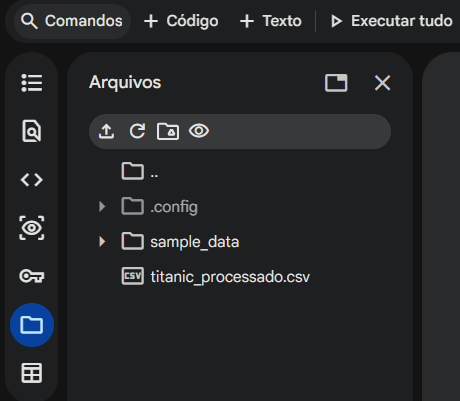


### ❗ Arquivos no Colab são temporários

Arquivos salvos no Colab são **temporários** e serão excluídos após o encerramento da sessão. Por isso, sempre baixe os arquivos importantes para o seu computador.

# 💡 Soluções

### Criando uma Series

```python
import numpy as np
import pandas as pd

# Gera valores aleatórios de precipitação para 356 dias
precipitacao = np.random.uniform(0, 85, 356)

# Cria os índices
indices = [f"Dia {i}" for i in range(1, 357)]

# Cria a Series
serie_precipitacao = pd.Series(precipitacao, index=indices)

# Exibe a Series
print(serie_precipitacao)

# Exibe o tipo dos dados armazenados
print(serie_precipitacao.dtype)
```

**Saída esperada (exemplo):**

```text
Dia 1      42.713498
Dia 2       5.214830
Dia 3      68.194253
...
Dia 355    11.084207
Dia 356    74.503189
Length: 356, dtype: float64

float64
```

### Criando um DataFrame

```python
import numpy as np
import pandas as pd

# Índices (dias)
lista_dias = [f"Dia {i+1}" for i in range(30)]

# Dados simulados
dicionario_dados = {
    "Temperatura_Motor_C": np.random.uniform(low=65, high=95, size=30),
    "Vibracao_mm_s": np.random.uniform(low=0.8, high=4.5, size=30),
    "Horas_Operacao": np.random.uniform(low=18, high=24, size=30),
    "Consumo_Energia_kWh": np.random.uniform(low=420, high=680, size=30)
}

# Cria o DataFrame
df = pd.DataFrame(dicionario_dados, index=lista_dias)

# Exibe as 8 primeiras linhas
print(df.head(8))
```

**Saída esperada (exemplo):**

```text
       Temperatura_Motor_C  Vibracao_mm_s  Horas_Operacao  Consumo_Energia_kWh
Dia 1             78.342115       1.982741        22.614837            634.817452
Dia 2             91.203684       3.451807        19.863491            487.263991
Dia 3             74.628153       1.207454        21.957331            548.120677
Dia 4             88.715429       2.734105        23.408191            663.875213
Dia 5             69.501237       4.186572        18.735448            421.906742
Dia 6             81.164893       2.091334        22.113760            596.148024
Dia 7             76.982304       3.615028        20.247138            509.274533
Dia 8             93.481576       1.456919        23.891275            646.508110
```

### Seleção com `loc`

```python
import pandas as pd

# Carregando dados em CSV usando URL.
df = pd.read_csv("https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv")

# 1. Seleciona a primeira linha completa
print(df.loc[0])
print()

# 2. Seleciona apenas gênero, idade e cidade de embarque
print(df.loc[0, ["sex", "age", "embarked"]])
```

**Saída esperada (exemplo):**

```text
survived                 0
pclass                   3
sex                   male
age                   22.0
sibsp                    1
parch                    0
fare                  7.25
embarked                 S
class                Third
who                    man
adult_male            True
deck                   NaN
embark_town    Southampton
alive                   no
alone                False
Name: 0, dtype: object

sex         male
age         22.0
embarked       S
Name: 0, dtype: object
```

### Seleção com `iloc`

```python
import pandas as pd

# Carregando dados em CSV usando URL.
df = pd.read_csv("https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv")

# 1. Seleciona a primeira linha completa
print(df.iloc[0])
print()

# 2. Seleciona apenas gênero, idade e cidade de embarque
print(df.iloc[0, [2, 3, 7]])
```

**Saída esperada (exemplo):**

```text
survived                 0
pclass                   3
sex                   male
age                   22.0
sibsp                    1
parch                    0
fare                  7.25
embarked                 S
class                Third
who                    man
adult_male            True
deck                   NaN
embark_town    Southampton
alive                   no
alone                False
Name: 0, dtype: object

sex         male
age         22.0
embarked       S
Name: 0, dtype: object
```

### Filtrando Dados com Condições

```python
# Carregando dados em CSV usando URL.
df = pd.read_csv("https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv")

# 1. Passageiros com idade maior que 30 anos
print(df[df["age"] > 30])
print("================")

# 2. Passageiras do sexo feminino
print(df[df["sex"] == "female"])
print("================")

# 3. Passageiros que embarcaram em Cherbourg e sobreviveram
print(df[(df["embark_town"] == "Cherbourg") & (df["survived"] == 1)])
```

**Saída esperada (exemplo):**

```text
     survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
1           1       1  female  38.0      1      0  71.2833        C  First   
3           1       1  female  35.0      1      0  53.1000        S  First   
4           0       3    male  35.0      0      0   8.0500        S  Third   
6           0       1    male  54.0      0      0  51.8625        S  First   
11          1       1  female  58.0      0      0  26.5500        S  First   
..        ...     ...     ...   ...    ...    ...      ...      ...    ...   
873         0       3    male  47.0      0      0   9.0000        S  Third   
879         1       1  female  56.0      0      1  83.1583        C  First   
881         0       3    male  33.0      0      0   7.8958        S  Third   
885         0       3  female  39.0      0      5  29.1250        Q  Third   
890         0       3    male  32.0      0      0   7.7500        Q  Third   

       who  adult_male deck  embark_town alive  alone  
1    woman       False    C    Cherbourg   yes  False  
3    woman       False    C  Southampton   yes  False  
4      man        True  NaN  Southampton    no   True  
6      man        True    E  Southampton    no   True  
11   woman       False    C  Southampton   yes   True  
..     ...         ...  ...          ...   ...    ...  
873    man        True  NaN  Southampton    no   True  
879  woman       False    C    Cherbourg   yes  False  
881    man        True  NaN  Southampton    no   True  
885  woman       False  NaN   Queenstown    no  False  
890    man        True  NaN   Queenstown    no   True  

[305 rows x 15 columns]
================
     survived  pclass     sex   age  sibsp  parch     fare embarked   class  \
1           1       1  female  38.0      1      0  71.2833        C   First   
2           1       3  female  26.0      0      0   7.9250        S   Third   
3           1       1  female  35.0      1      0  53.1000        S   First   
8           1       3  female  27.0      0      2  11.1333        S   Third   
9           1       2  female  14.0      1      0  30.0708        C  Second   
..        ...     ...     ...   ...    ...    ...      ...      ...     ...   
880         1       2  female  25.0      0      1  26.0000        S  Second   
882         0       3  female  22.0      0      0  10.5167        S   Third   
885         0       3  female  39.0      0      5  29.1250        Q   Third   
887         1       1  female  19.0      0      0  30.0000        S   First   
888         0       3  female   NaN      1      2  23.4500        S   Third   

       who  adult_male deck  embark_town alive  alone  
1    woman       False    C    Cherbourg   yes  False  
2    woman       False  NaN  Southampton   yes   True  
3    woman       False    C  Southampton   yes  False  
8    woman       False  NaN  Southampton   yes  False  
9    child       False  NaN    Cherbourg   yes  False  
..     ...         ...  ...          ...   ...    ...  
880  woman       False  NaN  Southampton   yes  False  
882  woman       False  NaN  Southampton    no   True  
885  woman       False  NaN   Queenstown    no  False  
887  woman       False    B  Southampton   yes   True  
888  woman       False  NaN  Southampton    no  False  

[314 rows x 15 columns]
================
     survived  pclass     sex   age  sibsp  parch      fare embarked   class  \
1           1       1  female  38.0      1      0   71.2833        C   First   
9           1       2  female  14.0      1      0   30.0708        C  Second   
19          1       3  female   NaN      0      0    7.2250        C   Third   
31          1       1  female   NaN      1      0  146.5208        C   First   
36          1       3    male   NaN      0      0    7.2292        C   Third   
..        ...     ...     ...   ...    ...    ...       ...      ...     ...   
866         1       2  female  27.0      1      0   13.8583        C  Second   
874         1       2  female  28.0      1      0   24.0000        C  Second   
875         1       3  female  15.0      0      0    7.2250        C   Third   
879         1       1  female  56.0      0      1   83.1583        C   First   
889         1       1    male  26.0      0      0   30.0000        C   First   

       who  adult_male deck embark_town alive  alone  
1    woman       False    C   Cherbourg   yes  False  
9    child       False  NaN   Cherbourg   yes  False  
19   woman       False  NaN   Cherbourg   yes   True  
31   woman       False    B   Cherbourg   yes  False  
36     man        True  NaN   Cherbourg   yes   True  
..     ...         ...  ...         ...   ...    ...  
866  woman       False  NaN   Cherbourg   yes  False  
874  woman       False  NaN   Cherbourg   yes  False  
875  child       False  NaN   Cherbourg   yes   True  
879  woman       False    C   Cherbourg   yes  False  
889    man        True    C   Cherbourg   yes   True  

[93 rows x 15 columns]
```

### Ordenação

```python
# Carregando dados em CSV usando URL.
df = pd.read_csv("https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv")

# 1. Ordena pela cidade de embarque em ordem decrescente
print(df.sort_values(by="embark_town", ascending=False))
print("===============")

# 2. Ordena primeiro pela cidade de embarque e depois pela idade
print(df.sort_values(by=["embark_town", "age"]))
```

**Saída esperada (exemplo):**

```text
     survived  pclass     sex   age  sibsp  parch      fare embarked  class  \
0           0       3    male  22.0      1      0    7.2500        S  Third   
554         1       3  female  22.0      0      0    7.7750        S  Third   
540         1       1  female  36.0      0      2   71.0000        S  First   
541         0       3  female   9.0      4      2   31.2750        S  Third   
542         0       3  female  11.0      4      2   31.2750        S  Third   
..        ...     ...     ...   ...    ...    ...       ...      ...    ...   
96          0       1    male  71.0      0      0   34.6542        C  First   
544         0       1    male  50.0      1      0  106.4250        C  First   
381         1       3  female   1.0      0      2   15.7417        C  Third   
61          1       1  female  38.0      0      0   80.0000      NaN  First   
829         1       1  female  62.0      0      0   80.0000      NaN  First   

       who  adult_male deck  embark_town alive  alone  
0      man        True  NaN  Southampton    no  False  
554  woman       False  NaN  Southampton   yes   True  
540  woman       False    B  Southampton   yes  False  
541  child       False  NaN  Southampton    no  False  
542  child       False  NaN  Southampton    no  False  
..     ...         ...  ...          ...   ...    ...  
96     man        True    A    Cherbourg    no   True  
544    man        True    C    Cherbourg    no  False  
381  child       False  NaN    Cherbourg   yes  False  
61   woman       False    B          NaN   yes   True  
829  woman       False    B          NaN   yes   True  

[891 rows x 15 columns]
===============
     survived  pclass     sex    age  sibsp  parch     fare embarked   class  \
803         1       3    male   0.42      0      1   8.5167        C   Third   
469         1       3  female   0.75      2      1  19.2583        C   Third   
644         1       3  female   0.75      2      1  19.2583        C   Third   
381         1       3  female   1.00      0      2  15.7417        C   Third   
827         1       2    male   1.00      0      2  37.0042        C  Second   
..        ...     ...     ...    ...    ...    ...      ...      ...     ...   
868         0       3    male    NaN      0      0   9.5000        S   Third   
878         0       3    male    NaN      0      0   7.8958        S   Third   
888         0       3  female    NaN      1      2  23.4500        S   Third   
61          1       1  female  38.00      0      0  80.0000      NaN   First   
829         1       1  female  62.00      0      0  80.0000      NaN   First   

       who  adult_male deck  embark_town alive  alone  
803  child       False  NaN    Cherbourg   yes  False  
469  child       False  NaN    Cherbourg   yes  False  
644  child       False  NaN    Cherbourg   yes  False  
381  child       False  NaN    Cherbourg   yes  False  
827  child       False  NaN    Cherbourg   yes  False  
..     ...         ...  ...          ...   ...    ...  
868    man        True  NaN  Southampton    no   True  
878    man        True  NaN  Southampton    no   True  
888  woman       False  NaN  Southampton    no  False  
61   woman       False    B          NaN   yes   True  
829  woman       False    B          NaN   yes   True  

[891 rows x 15 columns]
```

### Conversão de Tipos de Dados

```python
# Carregando dados em CSV usando URL.
df = pd.read_csv("https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv")

# 1. Verifica os tipos das colunas
print(df.dtypes)
print("============")

# 2. Converte a coluna "survived" para o tipo boolean
df["survived"] = df["survived"].astype(bool)

# 3. Converte a coluna "embarked" para o tipo category
df["embarked"] = df["embarked"].astype("category")

# Verifica novamente os tipos das colunas
print(df.dtypes)
```

**Saída esperada (exemplo):**

```text
survived         int64
pclass           int64
sex             object
age            float64
sibsp            int64
parch            int64
fare           float64
embarked        object
class           object
who             object
adult_male        bool
deck            object
embark_town     object
alive           object
alone             bool
dtype: object
============
survived           bool
pclass            int64
sex              object
age             float64
sibsp             int64
parch             int64
fare            float64
embarked       category
class            object
who              object
adult_male         bool
deck             object
embark_town      object
alive            object
alone              bool
dtype: object
```